## Teil 1 (5.1)

In [1]:
import pandas as pd
import numpy as np

pd.read_csv("../data/processed/kontext_monat.csv").columns.tolist()

['jahr',
 'monat',
 'eur_chf',
 'ferientage_de',
 'ferientage_ch',
 'ferientage_ch_annahme',
 'feiertage_ch']

In [2]:
panel = pd.read_csv("../data/processed/panel_winter.csv")
panel = panel.sort_values(["bfs_nr", "jahr", "monat"])
panel["schnee_saison"] = panel.groupby(["bfs_nr", "winter"])["schneefall_cm"].cumsum()
print(panel.shape, panel["bfs_nr"].nunique())      # erwartet: 2255 Zeilen, 45 Orte

(2255, 31) 45


Abweichungen statt Rohwerte: Wir messen, ob **derselbe Ort** bei mehr Schnee voller ist als sonst. Die Normalwerte stammen nur aus den Trainingswintern 2013/14–2021/22.

In [3]:
m = panel[panel.covid == 0].copy()                  # Corona-Monate entfernen

train_mask = m["winter"] <= 2021
norm = (m[train_mask].groupby(["bfs_nr", "monat"])
        [["zimmerauslastung", "schneefall_cm", "temp_mittel", "schnee_saison"]].mean()
        .add_suffix("_norm").reset_index())
m = m.merge(norm, on=["bfs_nr", "monat"], how="left")

m["y_abw"]             = m["zimmerauslastung"] - m["zimmerauslastung_norm"]   # Prozentpunkte
m["schnee_abw"]        = m["schneefall_cm"]    - m["schneefall_cm_norm"]      # cm
m["temp_abw"]          = m["temp_mittel"]      - m["temp_mittel_norm"]        # °C
m["schnee_saison_abw"] = m["schnee_saison"]    - m["schnee_saison_norm"]
print(len(m))                                        # erwartet: 2032


2032


In [4]:
m = m.sort_values(["bfs_nr", "jahr", "monat"])

# Kontext anhängen, falls nicht schon in den Daten
if "eur_chf" not in m.columns:
    kontext = pd.read_csv("../data/processed/kontext_monat.csv")
    n0 = len(m)
    m = m.merge(kontext, on=["jahr", "monat"], how="left", validate="m:1")
    assert len(m) == n0

m["schnee_vormonat"] = m.groupby(["bfs_nr", "winter"])["schneefall_cm"].shift(1)
if "sonnenstunden" in m.columns:                      # nur, falls nachgeladen
    m["sonne_abw"] = m["sonnenstunden"] - m.groupby(["bfs_nr", "monat"])["sonnenstunden"].transform("mean")

m["log_betten"]        = np.log(m["betten"])
m["anteil_ausland_vj"] = m.groupby(["bfs_nr", "monat"])["anteil_ausland"].shift(1)   # Vorjahr, kein Leakage
m["trend"]             = m["winter"] - 2013                                           # 0 = Winter 2013/14


Zeitlicher Split statt Zufall, damit das Modell nichts aus der Zukunft lernt.

In [5]:
train = m[m["winter"] <= 2021]      # Winter 2013/14 – 2021/22
test  = m[m["winter"] >= 2022]      # Winter 2022/23 – 2025/26
print(len(train), len(test), len(train) + len(test))    # Test ca. 720, zusammen 2032

1312 720 2032


In [6]:
print(train["winter"].max(), test["winter"].min())       # 2021 und 2022
print(train["covid"].sum() + test["covid"].sum())        # 0

neu = ["y_abw", "schnee_abw", "temp_abw", "schnee_saison_abw", "schnee_vormonat",
       "eur_chf", "ferientage_de", "ferientage_ch", "feiertage_ch",
       "log_betten", "anteil_ausland_vj", "trend"]
print(m[neu].isna().sum())
print(train[["y_abw", "schnee_abw", "temp_abw"]].describe())


2021 2022
0
y_abw                  0
schnee_abw             0
temp_abw               0
schnee_saison_abw      0
schnee_vormonat      520
eur_chf                0
ferientage_de          0
ferientage_ch          0
feiertage_ch           0
log_betten             0
anteil_ausland_vj    180
trend                  0
dtype: int64
              y_abw    schnee_abw      temp_abw
count  1.312000e+03  1.312000e+03  1.312000e+03
mean   7.040439e-17  3.899320e-16  1.353931e-17
std    5.797581e+00  2.410035e+01  1.829455e+00
min   -2.550000e+01 -6.656125e+01 -4.705645e+00
25%   -3.750000e+00 -1.538687e+01 -1.427722e+00
50%    0.000000e+00 -1.733125e+00  3.572581e-01
75%    3.428571e+00  1.332844e+01  1.275605e+00
max    2.185714e+01  1.504388e+02  5.593145e+00


In [7]:
print("ferientage_ch_annahme" in m.columns)  

True


## Teil 2:  Modelle (5.2)

In [8]:
import statsmodels.formula.api as smf
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

modellvars = ["y_abw", "schnee_abw", "temp_abw", "monat", "ostern_im_monat",
              "hoehenklasse", "hoehenklasse_1000", "schnee_vormonat", "eur_chf",
              "ferientage_de", "ferientage_ch", "feiertage_ch",
              "log_betten", "anteil_ausland_vj", "trend"]
train_k = train.dropna(subset=modellvars).copy()
test_k  = test.dropna(subset=modellvars).copy()
print(len(train_k), len(test_k), sorted(train_k["monat"].unique()))     # erwartet: 841 540 [1, 2, 3]

basis  = "schnee_abw + temp_abw + C(monat) + ostern_im_monat"
zusatz = ("schnee_vormonat + eur_chf + ferientage_de + ferientage_ch + feiertage_ch"
          " + log_betten + anteil_ausland_vj + trend")

mod_a = smf.ols(f"y_abw ~ {basis}", data=train_k).fit()
mod_b = smf.ols(f"y_abw ~ {basis} + {zusatz}", data=train_k).fit()
mod_c = smf.ols(f"y_abw ~ schnee_abw * C(hoehenklasse, Treatment('hoch')) "
                f"+ temp_abw + C(monat) + ostern_im_monat + {zusatz}", data=train_k).fit()

for name, mo in [("A", mod_a), ("B", mod_b), ("C", mod_c)]:
    print(name, "n =", int(mo.nobs), "R2 =", round(mo.rsquared, 3), "R2 adj =", round(mo.rsquared_adj, 3))
tab = pd.DataFrame({"coef": mod_c.params, "p": mod_c.pvalues}).round(3)
print(tab[~tab.index.str.contains("monat")].to_string())

841 540 [np.int64(1), np.int64(2), np.int64(3)]
A n = 841 R2 = 0.01 R2 adj = 0.004
B n = 841 R2 = 0.137 R2 adj = 0.123
C n = 841 R2 = 0.14 R2 adj = 0.123
                                                          coef      p
Intercept                                               -3.572  0.688
C(hoehenklasse, Treatment('hoch'))[T.mittel]            -0.050  0.923
C(hoehenklasse, Treatment('hoch'))[T.tief]               0.305  0.575
schnee_abw                                              -0.000  0.979
schnee_abw:C(hoehenklasse, Treatment('hoch'))[T.mittel]  0.001  0.967
schnee_abw:C(hoehenklasse, Treatment('hoch'))[T.tief]    0.041  0.116
temp_abw                                                -0.037  0.728
eur_chf                                                  3.266  0.600
ferientage_de                                           -0.778  0.102
ferientage_ch                                           -0.587  0.005
feiertage_ch                                             2.789  0.145
log_be

In [9]:
def kennzahlen(mod, df, name):
    pred = mod.predict(df)
    return {"modell": name, "n": len(df),
            "R2": r2_score(df["y_abw"], pred),
            "RMSE_pp": np.sqrt(mean_squared_error(df["y_abw"], pred)),
            "MAE_pp": mean_absolute_error(df["y_abw"], pred)}

resultate = pd.DataFrame([kennzahlen(mo, d, f"{n} {t}")
                          for n, mo in [("A", mod_a), ("B", mod_b), ("C", mod_c)]
                          for t, d in [("train", train_k), ("test", test_k)]])
null = np.zeros(len(test_k))
resultate.loc[len(resultate)] = {"modell": "Baseline test (immer 0)", "n": len(test_k),
    "R2": r2_score(test_k["y_abw"], null),
    "RMSE_pp": np.sqrt(mean_squared_error(test_k["y_abw"], null)),
    "MAE_pp": mean_absolute_error(test_k["y_abw"], null)}
resultate.round(3)

,modell,n,R2,RMSE_pp,MAE_pp
0,A train,841,0.010,5.747,4.406
1,A test,540,0.026,8.961,7.067
2,B train,841,0.137,5.366,4.014
3,B test,540,-0.185,9.885,7.705
4,C train,841,0.140,5.354,4.015
5,C test,540,-0.189,9.903,7.742
6,Baseline test (immer 0),540,-0.006,9.107,7.171


In [10]:
mk = m.dropna(subset=modellvars)
rob = {
  "ohne ferientage_ch": smf.ols(mod_c.model.formula.replace(" + ferientage_ch", ""), data=train_k).fit(),
  "nur echte CH-Ferien (ab 2021/22)": smf.ols(mod_c.model.formula, data=mk[(mk.winter >= 2021) & (mk.ferientage_ch_annahme == 0)]).fit(),
  "Grenze 1000 m": smf.ols(mod_c.model.formula.replace("C(hoehenklasse,", "C(hoehenklasse_1000,"), data=train_k).fit(),
}
pd.DataFrame({k: v.params.filter(like="schnee_abw") for k, v in rob.items()}).round(3)

C:\Users\Jelmer D'Hollosy\AppData\Local\Temp\ipykernel_20568\2301714617.py:4: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  "nur echte CH-Ferien (ab 2021/22)": smf.ols(mod_c.model.formula, data=mk[(mk.winter >= 2021) & (mk.ferientage_ch_annahme == 0)]).fit(),


,ohne ferientage_ch,nur echte CH-Ferien (ab 2021/22),Grenze 1000 m
schnee_abw,0.002,0.029,-0.001
"schnee_abw:C(hoehenklasse, Treatment('hoch'))[T.mittel]",-0.002,0.008,NaN
"schnee_abw:C(hoehenklasse, Treatment('hoch'))[T.tief]",0.034,0.079,NaN
"schnee_abw:C(hoehenklasse_1000, Treatment('hoch'))[T.mittel]",NaN,NaN,0.007
"schnee_abw:C(hoehenklasse_1000, Treatment('hoch'))[T.tief]",NaN,NaN,0.095


feiertage_ch         0.358
trend                0.323
ferientage_de       -0.236
ferientage_ch       -0.195
schnee_vormonat      0.076
anteil_ausland_vj    0.074
log_betten          -0.041
schnee_abw           0.026
temp_abw            -0.024
eur_chf              0.024
dtype: float64


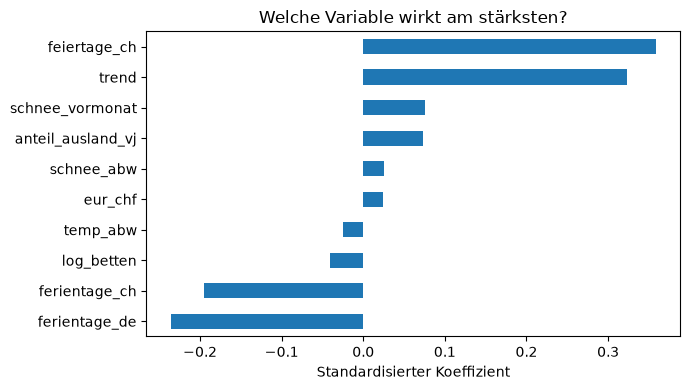

In [11]:
import matplotlib.pyplot as plt

num = ["schnee_abw", "temp_abw", "schnee_vormonat", "eur_chf", "ferientage_de", "ferientage_ch",
       "feiertage_ch", "log_betten", "anteil_ausland_vj", "trend"]
z = lambda s: (s - s.mean()) / s.std()
train_z = train_k.copy(); train_z[num + ["y_abw"]] = train_z[num + ["y_abw"]].apply(z)
mod_z = smf.ols(f"y_abw ~ {basis} + {zusatz}", data=train_z).fit()

koef = mod_z.params[num].sort_values(key=abs, ascending=False)
print(koef.round(3))
koef.sort_values().plot.barh(figsize=(7, 4))
plt.xlabel("Standardisierter Koeffizient"); plt.title("Welche Variable wirkt am stärksten?")
plt.tight_layout(); plt.savefig("../figures/standardisierte_koeffizienten.png", dpi=150); plt.show()

In [12]:
from statsmodels.stats.outliers_influence import variance_inflation_factor

spalten = num + ["ostern_im_monat"]
X = train_k[spalten].assign(const=1.0)
vif = pd.Series([variance_inflation_factor(X.values, i) for i in range(len(spalten))], index=spalten)
vif.round(2).sort_values(ascending=False)

ferientage_de        8.11
ostern_im_monat      5.23
feiertage_ch         3.17
ferientage_ch        3.03
eur_chf              1.44
schnee_abw           1.31
anteil_ausland_vj    1.26
log_betten           1.23
schnee_vormonat      1.21
trend                1.17
temp_abw             1.16
dtype: float64

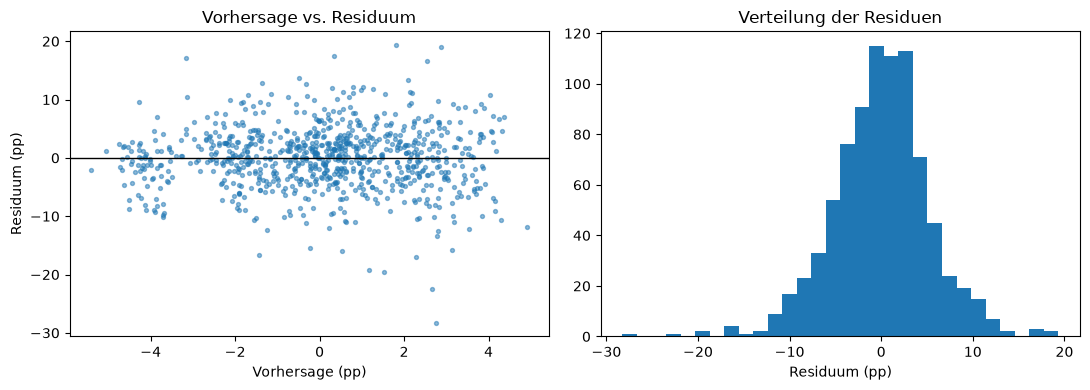

In [13]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].scatter(mod_c.fittedvalues, mod_c.resid, s=8, alpha=0.5); ax[0].axhline(0, color="black", lw=1)
ax[0].set_xlabel("Vorhersage (pp)"); ax[0].set_ylabel("Residuum (pp)"); ax[0].set_title("Vorhersage vs. Residuum")
ax[1].hist(mod_c.resid, bins=30); ax[1].set_xlabel("Residuum (pp)"); ax[1].set_title("Verteilung der Residuen")
plt.tight_layout(); plt.show()

In [14]:
print(m.groupby("winter")["y_abw"].mean().round(2))
print("Test-Mittel y_abw:", round(test_k["y_abw"].mean(), 2))

winter
2013    0.57
2014   -0.88
2015   -2.55
2016   -3.14
2017    0.24
2018    0.21
2019    3.13
2021    2.83
2022    2.38
2023    1.53
2024    1.56
2025    1.98
Name: y_abw, dtype: float64
Test-Mittel y_abw: 0.68


In [15]:
mod_c2 = smf.ols(mod_c.model.formula.replace(" + ferientage_de", ""), data=train_k).fit()
pd.DataFrame([kennzahlen(mod_c, train_k, "C train"), kennzahlen(mod_c2, train_k, "C ohne ferientage_de train"),
              kennzahlen(mod_c, test_k, "C test"), kennzahlen(mod_c2, test_k, "C ohne ferientage_de test")]).round(3)

,modell,n,R2,RMSE_pp,MAE_pp
0,C train,841,0.140,5.354,4.015
1,C ohne ferientage_de train,841,0.137,5.363,4.017
2,C test,540,-0.189,9.903,7.742
3,C ohne ferientage_de test,540,-0.202,9.957,7.771
